# Pais-Uhlenbeck con interaccion cuartica

Hamiltoniano truncado a la base de Fock par `|2k, 2l>`:

$$H' = \hbar\omega_1 N_a - \hbar\omega_2 N_b + \lambda Q_1^2 Q_2^2.$$

El estado inicial es `|0,0>`. La evolucion de abajo es exacta para el corte `K`, no una prueba de estabilidad en dimension infinita.

El orquestador esta en `src/pu_q/orquestador.py`. Las clases del modelo estan en `src/pu_q/clases/`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import numpy as np
from pu_q.clases import EvolucionUnitaria, VerificadorMatriz4x4
from pu_q.orquestador import Orquestador

## Comprobacion de la matriz 4x4

Para `K=1` la base es `|0,0>, |2,0>, |0,2>, |2,2>`.

In [3]:
sistema = VerificadorMatriz4x4().verificar(omega1=1.0, omega2=2.0, lam=0.2, hbar=1.0)

Comprobacion de matriz 4x4: CORRECTA
Orden de la base: |0,0>, |2,0>, |0,2>, |2,2>
[[ 0.025     0.035355  0.035355  0.05    ]
 [ 0.035355  2.125     0.05      0.176777]
 [ 0.035355  0.05     -3.875     0.176777]
 [ 0.05      0.176777  0.176777 -1.375   ]]


## Un corte pequeno

`EvolucionUnitaria` construye `H_K` y devuelve `<N>`, la varianza, la probabilidad de vacio y la masa en el borde.

In [4]:
K = 4
tiempos = np.linspace(0.0, 2.0, 41)
datos = EvolucionUnitaria(K, omega1=1.0, omega2=2.0, lam=0.2, hbar=1.0).evolucionar(tiempos)
{
    "dimension": datos["dimension"],
    "E0": datos["E0"],
    "max|norma-1|": float(np.max(np.abs(datos["norma"] - 1.0))),
    "N(t_final)": float(datos["N"][-1]),
}

{'dimension': 25,
 'E0': 0.025,
 'max|norma-1|': 1.7763568394002505e-15,
 'N(t_final)': 0.023018112401078837}

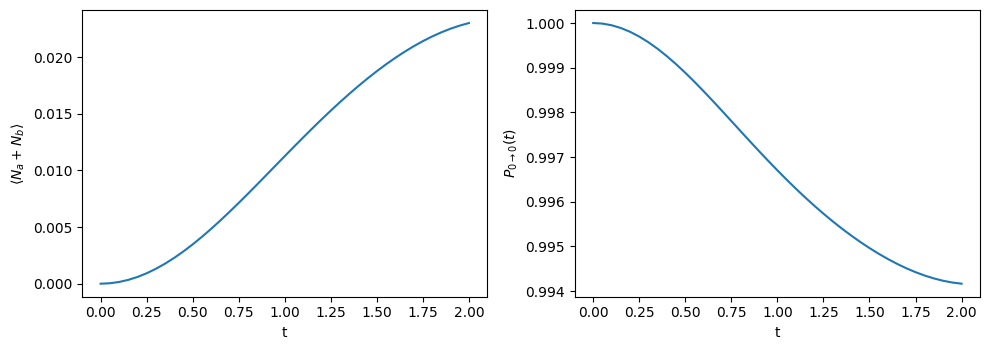

In [5]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
ejes[0].plot(datos["t"], datos["N"])
ejes[0].set_xlabel("t")
ejes[0].set_ylabel(r"$\langle N_a+N_b\rangle$")
ejes[1].plot(datos["t"], datos["P0"])
ejes[1].set_xlabel("t")
ejes[1].set_ylabel(r"$P_{0\to 0}(t)$")
fig.tight_layout()

## Barrido corto de cortes

`Orquestador(..., quick=True)` usa `K = 1, 4, 8`, `tmax = 2` y escribe CSV y PNG en `resultados_notebook/`.

In [6]:
Orquestador(
    omega2="2",
    outdir=RAIZ / "resultados_notebook",
).ejecutar()

Comprobacion de matriz 4x4: CORRECTA
Orden de la base: |0,0>, |2,0>, |0,2>, |2,2>
[[ 0.025     0.035355  0.035355  0.05    ]
 [ 0.035355  2.125     0.05      0.176777]
 [ 0.035355  0.05     -3.875     0.176777]
 [ 0.05      0.176777  0.176777 -1.375   ]]

Simulando omega1=1, omega2=2, lambda=0.2, hbar=1
  Calculando K=12, dimension=169...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_12.csv
  Calculando K=40, dimension=1681...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_40.csv
  Calculando K=60, dimension=3721...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_60.csv
  Calculando K=80, dimension=6561...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_80.csv
  Calculando K=100, dimension=10201...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_100.cs

## Cola del numero medio

No subimos mas el corte. Con las $p_q$ ya guardadas medimos la parte de $\langle N\rangle$ que viene de los estados con $M$ o mas excitaciones:

$$
R_M^{(K)}(t)=\sum_{2q\ge M} 2q\, p_q^{(K)}(t).
$$

$R_0^{(K)}(t)$ coincide con $\langle N\rangle_t$. Como la base par solo tiene $N=0,2,4,\ldots$, tambien $R_2=R_0$: el vacio no aporta al numero.


In [7]:
from pu_q.clases import (
    ContribucionColaRM,
    ExportadorContribucionCola,
    GraficadorContribucionCola,
    LectorDistribucionPq,
)

SALIDA = RAIZ / "resultados_notebook"
lector_pq = LectorDistribucionPq()
cola = ContribucionColaRM()
curvas_rm = {}
tiempos_rm = None
for ruta in sorted(SALIDA.glob("pu_omega2_2_K_*_pq_todos_los_tiempos.csv")):
    corte = int(ruta.name.split("_K_")[1].split("_")[0])
    tiempos_rm, prob_q = lector_pq.leer(ruta)
    curvas_rm[corte] = cola.calcular(prob_q)
    ExportadorContribucionCola().exportar(
        SALIDA / f"pu_omega2_2_K_{corte}_rm.csv", tiempos_rm, curvas_rm[corte]
    )

print("Cortes:", sorted(curvas_rm))
print("Umbrales M:", list(next(iter(curvas_rm.values()))))


Cortes: [12, 40, 60, 80, 100, 120, 140]
Umbrales M: [0, 2, 4, 8, 16, 32, 64, 128, 256]


In [8]:
umbrales = list(next(iter(curvas_rm.values())))
print("R_M(t_final)")
print("M".rjust(6) + "".join(f"{K:12d}" for K in sorted(curvas_rm)))
for umbral in umbrales:
    linea = f"{umbral:6d}"
    for corte in sorted(curvas_rm):
        linea += f"{curvas_rm[corte][umbral][-1]:12.6g}"
    print(linea)

corte_max = max(curvas_rm)
referencia = curvas_rm[corte_max][0][-1]
print(f"\nFraccion R_M/R_0 en t_final, K={corte_max}, <N>={referencia:.6f}")
for umbral in umbrales:
    valor = curvas_rm[corte_max][umbral][-1]
    print(f"  M={umbral:4d}  fraccion={valor / referencia:.4f}")


R_M(t_final)
     M          12          40          60          80         100         120         140
     0    0.022245   0.0330222   0.0399991   0.0443803   0.0477659   0.0494089   0.0503686
     2    0.022245   0.0330222   0.0399991   0.0443803   0.0477659   0.0494089   0.0503686
     4   0.0218696   0.0326448   0.0396215   0.0440028   0.0473884   0.0490314   0.0499911
     8   0.0112217   0.0222223   0.0292065   0.0335791   0.0369666   0.0386092   0.0395693
    16  0.00904622   0.0200606   0.0270106    0.031427   0.0348049   0.0364524   0.0374088
    32   0.0042305   0.0171861   0.0245298   0.0289088   0.0323388   0.0339998   0.0349668
    64           0   0.0120791   0.0211083   0.0255603   0.0291159   0.0307917   0.0317246
   128           0  0.00168153   0.0100586   0.0175739   0.0216062   0.0233612   0.0243953
   256           0           0           0  0.00158522  0.00645841  0.00913038    0.010715

Fraccion R_M/R_0 en t_final, K=140, <N>=0.050369
  M=   0  fraccion=1.0000
 

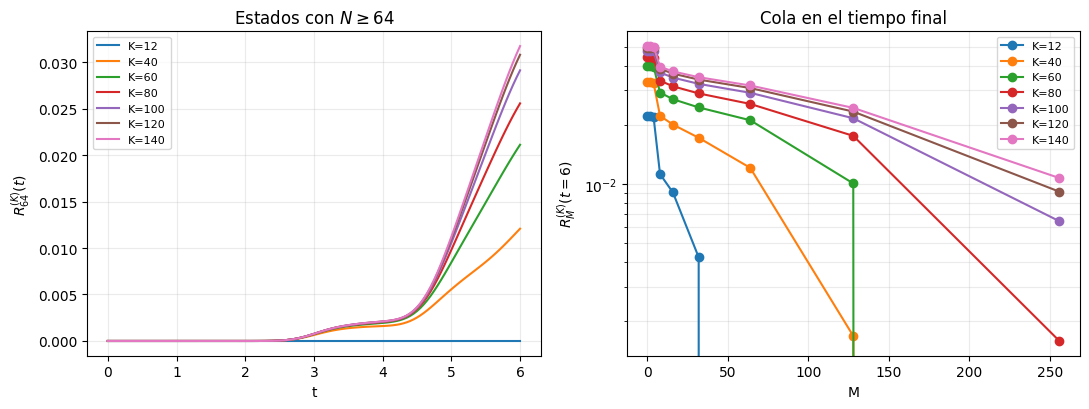

In [9]:
GraficadorContribucionCola().graficar_en_tiempo(
    tiempos_rm,
    curvas_rm,
    SALIDA / "rm_tiempo_omega2_2.png",
    r"Contribucion de la cola ($\omega_2=2$)",
)
GraficadorContribucionCola().graficar_frente_a_umbral(
    curvas_rm,
    SALIDA / "rm_umbral_omega2_2.png",
    r"$R_M$ en $t=6$ ($\omega_2=2$)",
)

import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
for corte, curvas in sorted(curvas_rm.items()):
    ejes[0].plot(tiempos_rm, curvas[64], label=f"K={corte}")
    ejes[1].semilogy(
        list(curvas), [curvas[umbral][-1] for umbral in curvas], marker="o", label=f"K={corte}"
    )
ejes[0].set_xlabel("t")
ejes[0].set_ylabel(r"$R_{64}^{(K)}(t)$")
ejes[0].set_title(r"Estados con $N\geq 64$")
ejes[0].grid(alpha=0.25)
ejes[0].legend(fontsize=8)
ejes[1].set_xlabel("M")
ejes[1].set_ylabel(r"$R_M^{(K)}(t=6)$")
ejes[1].set_title("Cola en el tiempo final")
ejes[1].grid(alpha=0.25, which="both")
ejes[1].legend(fontsize=8)
fig.tight_layout()


En $t=6$ y $\omega_2=2$, con $K=140$, cerca de un 63 % de $\langle N\rangle$ sale de $N\ge 64$ y un 21 % de $N\ge 256$. Hasta $t\approx 2$ esa cola es despreciable y no depende del corte. A tiempos mayores, $R_M$ sigue creciendo al pasar de $K=120$ a $K=140$: el numero medio todavia recibe aportacion del borde del truncamiento.
